# MEG theta power around button presses

For every finite button-press time and MEG sensor, this notebook computes 2–5 Hz power in the 1-second window from −0.5 to +0.5 s around the press. The MEG epochs start 2.8 s before the fractal-cue time zero, so the behavioral press times are shifted by `chan_delay` before epoching.

Each press is baseline corrected against the 2–5 Hz power in the [−1s, 0s] window before that trial's cue, using 10 × log10(press power / trial baseline power). The final scalp map shows the mean dB change over valid presses. the 1-second window gives 1 Hz FFT bins.

import toolboxes

In [32]:
import h5py
import mne 
import numpy as np
import matplotlib.pyplot as plt
import os

define variables

defualt parameters:  

theta frequency band = 2-5 Hz   
button press time window = [-0.5s,0.5s]  
time window for baseline calculation = [-1s,0s]  
channel signal delay (chan_delay) = 2.8 seconds  
total trial time (trial_time) = 14.8 seconds  
sample frequency (sfreqs) = 1000Hz
number of trials (n_trials) = 240
number of button presses per trial (n_press_slots) = 5

In [33]:
sub_ID = input('subject ID:')
theta_freq_band = np.array([2,5])
press_time_wind = np.array([-0.5,0.5])
baseline_time_wind = np.array([-1,0])
MEG_chan = list()
chan_delay = 2.8
trial_time = 14.8
sfreq = 1000
n_trials = 240
n_press_slots = 5
ch_types = ['meg'] * 275

load subject files for button press times data (in beh data) and the MEG channel data. 

variables:

id = subject ID number in 2 digit format (e.g. 05, 10)   
spliced_id = subject ID in single digit format (e.g. 5, 8)  
CD_file = MNE data filepath  
BP1 = filepath for button timings and presses array  
BP2 = filepath for cue duration array  
CD = MNE data epochs object

outputs:

  
PT = press times array  
PRES = button press IDs for each trial array  
CD = data in the form of epochs object (n_epochs, n_channels, n_times)

In [34]:
def filename_loader(id):

    # define file directories for behavioural data in beh_data folder
    subject_folder = "//rdp.arc.ucl.ac.uk/ritd-ag-project-rd01pz-dbush99/Katja Button Press Data"
    button_press_folder = '/beh_data/s'+str(id)
    BP1 = subject_folder + button_press_folder + "/behDataMEG.mat"
    BP2 = subject_folder + button_press_folder + "/targetMEG.mat"


    # define file directories for .fif MNE files in subject folder
    if sub_ID.startswith('0'):
        spliced_id = id[1:]
        EMG_file ='/s0'+str(spliced_id)+'/Subject'+str(spliced_id)+'_spm_mne-epo'
    else:
        EMG_file ='/s'+str(id)+'/Subject'+str(id)+'_spm_mne-epo'
    CD_file = subject_folder + EMG_file + '.fif'

    # load behavioural data
    with h5py.File(BP1, 'r') as f:
        timings = f['A/timing'][:]
        presses = f['A/press'][:]
    timings = timings.T

    PRES = presses.T

    with h5py.File(BP2, 'r') as f:
        cuedur = f['T/cueDur'][:]
    cuedur = cuedur.T

    PT = (timings + np.tile(cuedur,5)) / 1000

    # load MNE file data
    CD = mne.read_epochs(CD_file, preload=True)

    # isolate all MEG channel names, stored in MEG_chan
    for i in CD.info['ch_names']:
        if i.startswith('M'):
            MEG_chan.append(i)
    # update sample frequency for MNE file
    sfreq = float(CD.info["sfreq"])

    # return outputs
    return PT,PRES,CD



press_times, presses, data = filename_loader(sub_ID)

Reading \\rdp.arc.ucl.ac.uk\ritd-ag-project-rd01pz-dbush99\Katja Button Press Data\s05\Subject5_spm_mne-epo.fif ...
    Found the data of interest:
        t =       0.00 ...   14800.00 ms
        0 CTF compensation matrices available
Reading \\rdp.arc.ucl.ac.uk\ritd-ag-project-rd01pz-dbush99\Katja Button Press Data\s05\Subject5_spm_mne-epo.fif ...
    Found the data of interest:
        t =       0.00 ...   14800.00 ms
        0 CTF compensation matrices available
Reading \\rdp.arc.ucl.ac.uk\ritd-ag-project-rd01pz-dbush99\Katja Button Press Data\s05\Subject5_spm_mne-epo.fif ...
    Found the data of interest:
        t =       0.00 ...   14800.00 ms
        0 CTF compensation matrices available
Not setting metadata
240 matching events found
No baseline correction applied
0 projection items activated


check all loaded data information. plots MEG signal of first trial from 4 MEG channels

press times array: [[3.394 4.64  5.302 5.944 6.671]
 [3.389 4.659 5.329 5.959 6.665]
 [3.468 4.795 5.438 6.089 6.796]
 ...
 [3.095 3.775 5.115 5.758 6.43 ]
 [3.265 4.001 5.324 5.982 6.665]
 [2.921 3.646 4.911 5.564 6.243]]


press times shape: (240, 5)


press sequence array:[[3. 4. 2. 5. 1.]
 [3. 4. 2. 5. 1.]
 [3. 4. 2. 5. 1.]
 ...
 [3. 4. 2. 5. 1.]
 [3. 4. 2. 5. 1.]
 [3. 4. 2. 5. 1.]]


presses array shape (240, 5)
<Info | 11 non-empty values
 bads: []
 ch_names: UPPT001, UPPT002, SCLK01, BG1, BG2, BG3, BP1, BP2, BP3, BR1, ...
 chs: 2 Stimulus, 33 misc, 29 Reference Magnetometers, 273 Magnetometers, 4 EMG
 custom_ref_applied: False
 dev_head_t: MEG device -> head transform
 dig: 7 items (3 Cardinal, 4 EEG)
 file_id: 4 items (dict)
 highpass: 0.0 Hz
 lowpass: 500.0 Hz
 meas_date: unspecified
 meas_id: 4 items (dict)
 nchan: 341
 projs: []
 sfreq: 1000.0 Hz
>
MEG Channel Names: ['UPPT001', 'UPPT002', 'SCLK01', 'BG1', 'BG2', 'BG3', 'BP1', 'BP2', 'BP3', 'BR1', 'BR2', 'BR3', 'G11', 'G12',

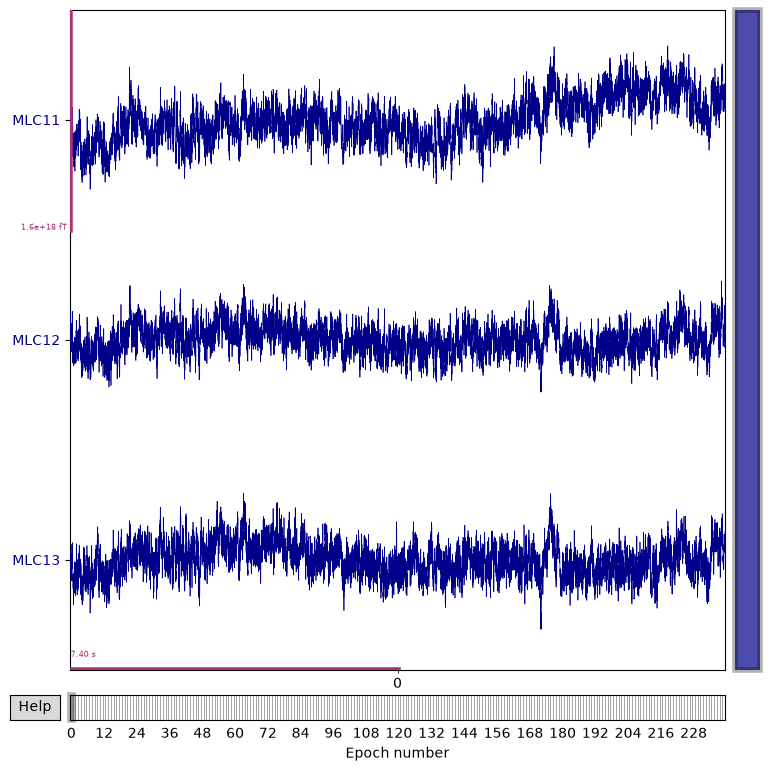

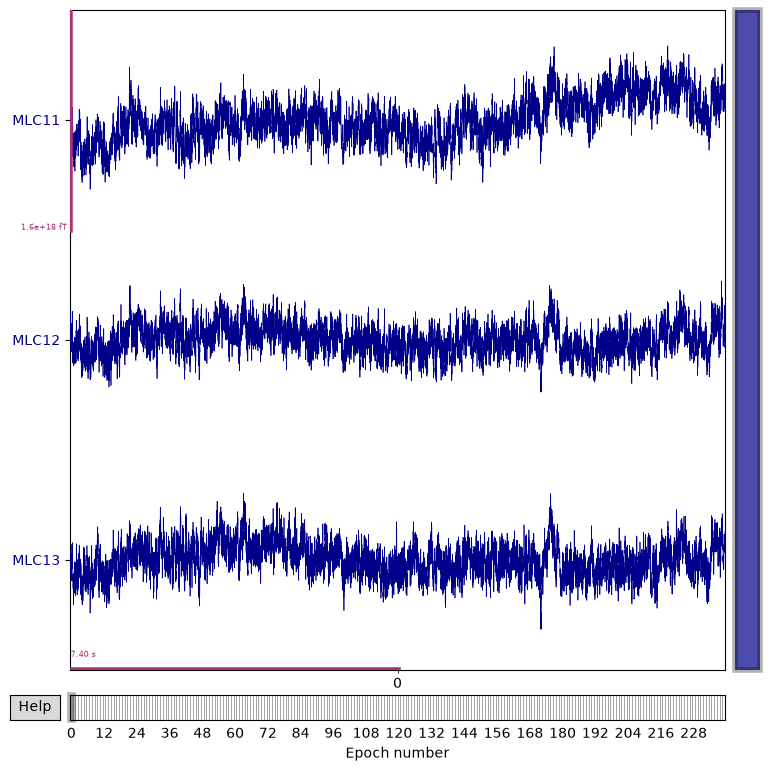

In [36]:
print(f'press times array: {press_times}')
print('\n')
print(f'press times shape: {press_times.shape}')
print('\n')
print(f'press sequence array:{presses}')
print('\n')
print(f'presses array shape {presses.shape}')

print(data.info)
print(f'MEG Channel Names: {data.info["ch_names"]}')

# plot first 4 MEG channels from MEG_chan
data.plot(n_epochs=1,n_channels=4,picks=MEG_chan[0:3],block=True,scalings=800,show=True,)

plot signal from button press channel against button press times

C:\Users\chick\AppData\Local\Temp\ipykernel_83012\1387948477.py:27: UserWarning: Legend does not support handles for str instances.
A proxy artist may be used instead.
See: https://matplotlib.org/stable/users/explain/axes/legend_guide.html#controlling-the-legend-entries
  plt.legend(['Channel signal'],['Button Press'])


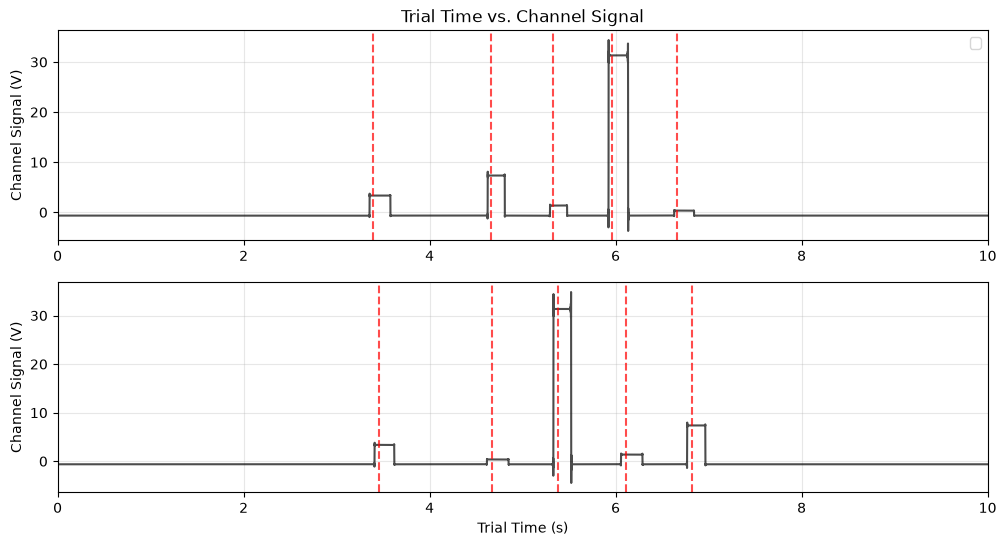

In [37]:
# isolate button press signal channel and fix time offset between channel signal and press times by channel delay
BP_chan = data.get_data(picks='UPPT002')[:,0,:]
BP_rolled = np.roll(BP_chan, -int(chan_delay * data.info['sfreq']), axis=1)


def UPPT002_plot(trial1,trial2):

    plt.figure(figsize=(12, 6))
    plt.title('Trial Time vs. Channel Signal')
    plt.axis('off')

    plt.subplot(2,1,1)
    plt.plot(data.times, BP_rolled[trial1],
            color='black',
            alpha=0.7,
            )

    for idx,pt in enumerate(press_times[trial1]):
        plt.axvline(
            x=pt,
            color='r',
            linestyle='--',
            alpha=0.7,
            )
    plt.ylabel('Channel Signal (V)')
    plt.xlim([0, 10])
    plt.legend(['Channel signal'],['Button Press'])
    plt.grid(alpha=0.3,which='both',axis='both')

    plt.subplot(2,1,2)
    plt.plot(data.times, BP_rolled[trial2],
            color='black',
            alpha=0.7,
            )

    for idx,pt in enumerate(press_times[trial2]):
        plt.axvline(
            x=pt,
            color='r',
            linestyle='--',
            alpha=0.7,
            )
    plt.xlabel('Trial Time (s)')
    plt.ylabel('Channel Signal (V)')
    plt.xlim([0, 10])
    plt.grid(alpha=0.3,which='both',axis='both')
    plt.show()

UPPT002_plot(1,7)

convert MNE epochs object back into raw file

In [38]:
# Join the stored epochs while retaining their original MEG sensor locations.
MEG_data = data.get_data(picks=MEG_chan)
n_epochs, n_channels, n_times = MEG_data.shape

# Use the actual number of samples in each stored epoch for trial offsets.
trial_time = n_times / sfreq
MEG_data = MEG_data.transpose(1, 0, 2).reshape(n_channels, n_epochs * n_times)

# Keep the sensor geometry from the loaded FIF file for topomap plotting.
meg_picks = mne.pick_channels(data.info["ch_names"], include = MEG_chan)
info = mne.pick_info(data.info, meg_picks, copy=True)
raw = mne.io.RawArray(MEG_data, info, verbose=False)

In [39]:
def press_time_flattener(pt_arr):
    pt_arr = np.asarray(pt_arr, dtype=float)
    if pt_arr.ndim != 2:
        raise ValueError(f"Expected a trials-by-presses array, got shape {pt_arr.shape}")
    if pt_arr.shape[0] != n_epochs:
        raise ValueError(
            f"Behavior has {pt_arr.shape[0]} trials but the MEG file has {n_epochs} epochs"
        )

    n_trials, n_press_slots = pt_arr.shape
    trial_offsets = np.arange(n_trials, dtype=float) * trial_time

    # Stored MEG epochs begin chan_delay seconds before cue-relative behavioral time zero.
    press_times_shifted = pt_arr + chan_delay + trial_offsets[:, None]
    trial_cutoff_times = chan_delay + trial_offsets

    valid = np.isfinite(press_times_shifted)
    press_trial_indices = np.broadcast_to(
        np.arange(n_trials)[:, None], (n_trials, n_press_slots)
    )[valid]

    print(f"Removed {(~valid).sum()} missing/non-finite press times")
    return press_times_shifted[valid], trial_cutoff_times, press_trial_indices


press_times_shifted, trial_cutoff_times, press_trial_indices = press_time_flattener(press_times)

Removed 1 missing/non-finite press times


In [40]:
def epochs_maker(r, events, wind, name):
    samples = np.rint(np.asarray(events, dtype=float) * sfreq).astype(int)
    event_array = np.column_stack([
        samples,
        np.zeros(len(samples), dtype=int),
        np.ones(len(samples), dtype=int),
    ])

    # MNE treats tmax as inclusive. Subtract one sample to make each requested
    # [start, stop) interval exactly 1 second long at the current sampling rate.
    epoch = mne.Epochs(
        r,
        event_array,
        event_id={"event": 1},
        tmin=float(wind[0]),
        tmax=float(wind[1]) - 1.0 / sfreq,
        baseline=None,
        preload=True,
        verbose=False,
    )

    print(f"{name} epochs object info:")
    print(epoch.info)
    return epoch


press_epochs = epochs_maker(raw, press_times_shifted, press_time_wind, "press")
baseline_epochs = epochs_maker(raw, trial_cutoff_times, baseline_time_wind, "baseline")

press epochs object info:
<Info | 11 non-empty values
 bads: []
 ch_names: MLC11, MLC12, MLC13, MLC14, MLC15, MLC16, MLC17, MLC21, MLC22, ...
 chs: 273 Magnetometers
 custom_ref_applied: False
 dev_head_t: MEG device -> head transform
 dig: 7 items (3 Cardinal, 4 EEG)
 file_id: 4 items (dict)
 highpass: 0.0 Hz
 lowpass: 500.0 Hz
 meas_date: unspecified
 meas_id: 4 items (dict)
 nchan: 273
 projs: []
 sfreq: 1000.0 Hz
>
baseline epochs object info:
<Info | 11 non-empty values
 bads: []
 ch_names: MLC11, MLC12, MLC13, MLC14, MLC15, MLC16, MLC17, MLC21, MLC22, ...
 chs: 273 Magnetometers
 custom_ref_applied: False
 dev_head_t: MEG device -> head transform
 dig: 7 items (3 Cardinal, 4 EEG)
 file_id: 4 items (dict)
 highpass: 0.0 Hz
 lowpass: 500.0 Hz
 meas_date: unspecified
 meas_id: 4 items (dict)
 nchan: 273
 projs: []
 sfreq: 1000.0 Hz
>


Retained button presses: 1199
theta_db_by_press shape (presses, sensors): (1199, 273)
Sensor order is the channel order in MEG_chan.


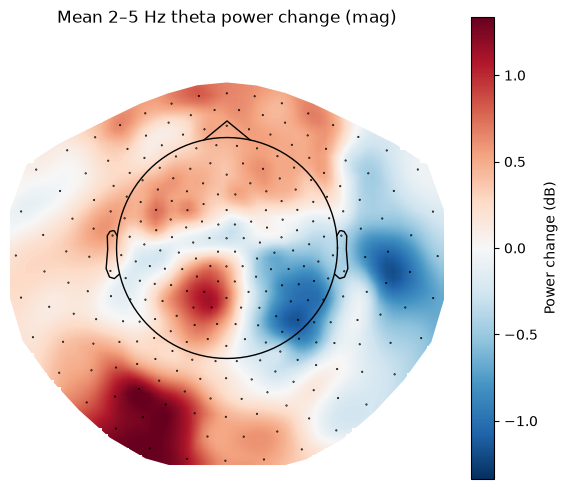

In [42]:
def mean_band_power(epochs, band):
    """Hann-window periodogram integrated over an inclusive frequency band."""
    x = epochs.get_data(picks=MEG_chan)
    fs = float(epochs.info["sfreq"])
    n_times = x.shape[-1]
    if not np.isclose(n_times / fs, 1.0):
        raise ValueError(
            f"Expected a 1-second epoch, got {n_times / fs:.6f} seconds"
        )

    # Demean each sensor/epoch, taper, then form a one-sided power spectral density.
    window = np.hanning(n_times)
    x = x - x.mean(axis=-1, keepdims=True)
    fft = np.fft.rfft(x * window, axis=-1)
    psd = (np.abs(fft) ** 2) / (fs * np.sum(window ** 2))
    if n_times % 2 == 0:
        psd[..., 1:-1] *= 2.0
    else:
        psd[..., 1:] *= 2.0

    freqs = np.fft.rfftfreq(n_times, d=1.0 / fs)
    in_band = (freqs >= band[0]) & (freqs <= band[1])
    if in_band.sum() < 2:
        raise ValueError("The selected frequency band has fewer than two FFT bins")

    # Trapezoidal integration works across the inclusive 2–5 Hz bins.
    band_psd = psd[..., in_band]
    band_freqs = freqs[in_band]
    return np.sum(
        0.5 * (band_psd[..., 1:] + band_psd[..., :-1]) * np.diff(band_freqs),
        axis=-1,
    )


# Arrays are in (press, sensor) and (trial, sensor) order, respectively.
theta_power_by_press = mean_band_power(press_epochs, theta_freq_band)
theta_power_baseline_by_epoch = mean_band_power(baseline_epochs, theta_freq_band)

# Match each press to its own trial baseline using MNE's original-event selections.
theta_baseline_by_trial = np.full(
    (len(trial_cutoff_times), len(MEG_chan)), np.nan, dtype=float
)
theta_baseline_by_trial[baseline_epochs.selection] = theta_power_baseline_by_epoch

press_trial_ids = press_trial_indices[press_epochs.selection]
theta_baseline_for_press = theta_baseline_by_trial[press_trial_ids]
has_baseline = np.isfinite(theta_baseline_for_press).any(axis=1)

theta_power_by_press = theta_power_by_press[has_baseline]
theta_baseline_for_press = theta_baseline_for_press[has_baseline]
press_trial_ids = press_trial_ids[has_baseline]
press_times_used = press_times_shifted[press_epochs.selection][has_baseline]

if len(theta_power_by_press) == 0:
    raise RuntimeError("No button presses have both a valid press epoch and trial baseline")

# Log-ratio baseline correction, in dB, for every retained press and MEG sensor.
theta_db_by_press = np.full(theta_power_by_press.shape, np.nan, dtype=float)
valid_power = (
    np.isfinite(theta_power_by_press)
    & np.isfinite(theta_baseline_for_press)
    & (theta_power_by_press > 0)
    & (theta_baseline_for_press > 0)
)
power_ratio = np.ones_like(theta_power_by_press)
np.divide(
    theta_power_by_press,
    theta_baseline_for_press,
    out=power_ratio,
    where=valid_power,
)
theta_db_by_press[valid_power] = 10.0 * np.log10(power_ratio[valid_power])

sensor_counts = np.isfinite(theta_db_by_press).sum(axis=0)
theta_db_mean = np.divide(
    np.nansum(theta_db_by_press, axis=0),
    sensor_counts,
    out=np.full(len(MEG_chan), np.nan),
    where=sensor_counts > 0,
)

print(f"Retained button presses: {len(press_times_used)}")
print(f"theta_db_by_press shape (presses, sensors): {theta_db_by_press.shape}")
print("Sensor order is the channel order in MEG_chan.")

# Plot one topomap per MEG sensor type (e.g. grad or mag).
sensor_types = [mne.channel_type(info, idx) for idx in range(len(MEG_chan))]
for sensor_type in sorted(set(sensor_types)):
    picks = np.array(
        [idx for idx, kind in enumerate(sensor_types) if kind == sensor_type],
        dtype=int,
    )
    sensor_info = mne.pick_info(info, picks, copy=True)
    fig, ax = plt.subplots(figsize=(7, 6))
    image, _ = mne.viz.plot_topomap(
        theta_db_mean[picks],
        sensor_info,
        ch_type=sensor_type,
        axes=ax,
        cmap="RdBu_r",
        contours=0,
        show=False,
    )
    ax.set_title(f"Mean 2–5 Hz theta power change ({sensor_type})")
    fig.colorbar(image, ax=ax, label="Power change (dB)")

plt.show()